<a href="https://colab.research.google.com/github/sajidkrim/Ultra_Thin_metamaterial_ML-_project/blob/main/ultra_thin_ML%20_part.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()  # select all 10 CSV files at once

Saving Bending_5-30- TM.csv to Bending_5-30- TM.csv
Saving Bending_5-30-TE.csv to Bending_5-30-TE.csv
Saving Period2_15.5-17.5.csv to Period2_15.5-17.5.csv
Saving phi_0-180-TE.csv to phi_0-180-TE.csv
Saving phi_0-180-TM.csv to phi_0-180-TM.csv
Saving Theta=10-80_TE.csv to Theta=10-80_TE.csv
Saving Theta=10-80_TM.csv to Theta=10-80_TM.csv
Saving Thickness_ground_3-15.csv to Thickness_ground_3-15.csv
Saving Thickness_substrate_8-24.csv to Thickness_substrate_8-24.csv
Saving Thickness_Top_2-6.csv to Thickness_Top_2-6.csv


parse and combine all files

In [ ]:
import pandas as pd
import numpy as np
import re
import io

def parse_cst_csv(filename, content):
    lines = content.decode("utf-8").splitlines()

    # Extract parameter values from header line 1
    param_line = lines[0]
    params = {}
    for match in re.finditer(r'(\w+)=([\d.]+)', param_line):
        params[match.group(1)] = float(match.group(2))

    # Extract column name from line 2 to detect varying parameter
    col_line = lines[1]

    # Read only data rows (skip lines starting with #)
    data_lines = [l for l in lines if not l.startswith('#') and l.strip()]
    data = pd.read_csv(io.StringIO('\n'.join(data_lines)),
                       sep='\t', header=None,
                       names=['wavelength_nm', 'absorption'])

    # Attach fixed parameters as columns
    data['hg']    = params.get('hg',  4.0)    # top layer thickness
    data['tn']    = params.get('tn',  9.0)    # ground thickness
    data['ts']    = params.get('ts',  16.0)   # substrate thickness
    data['p']     = params.get('p',   66.0)   # period
    data['phi']   = params.get('phi', 0.0)    # polarization angle
    data['theta'] = params.get('theta', 0.0)  # incident angle
    data['B']     = params.get('B',   0.0)    # bending
    data['source'] = filename

    return data

all_dfs = []
for filename, content in uploaded.items():
    df = parse_cst_csv(filename, content)
    all_dfs.append(df)
    print(f"✓ {filename} → {len(df)} rows")

combined = pd.concat(all_dfs, ignore_index=True)
print(f"\nTotal rows: {len(combined)}")
combined.head()

✓ Bending_5-30- TM.csv → 6048 rows
✓ Bending_5-30-TE.csv → 6048 rows
✓ Period2_15.5-17.5.csv → 5040 rows
✓ phi_0-180-TE.csv → 9072 rows
✓ phi_0-180-TM.csv → 9072 rows
✓ Theta=10-80_TE.csv → 8064 rows
✓ Theta=10-80_TM.csv → 8064 rows
✓ Thickness_ground_3-15.csv → 5040 rows
✓ Thickness_substrate_8-24.csv → 5040 rows
✓ Thickness_Top_2-6.csv → 5040 rows

Total rows: 66528


,wavelength_nm,absorption,hg,tn,ts,p,phi,theta,B,source
0,300.000000,0.943341,4.0,9.0,16.0,66.0,0.0,0.0,5.0,Bending_5-30- TM.csv
1,300.277757,0.943492,4.0,9.0,16.0,66.0,0.0,0.0,5.0,Bending_5-30- TM.csv
2,300.556029,0.943642,4.0,9.0,16.0,66.0,0.0,0.0,5.0,Bending_5-30- TM.csv
3,300.834817,0.943792,4.0,9.0,16.0,66.0,0.0,0.0,5.0,Bending_5-30- TM.csv
4,301.114122,0.943941,4.0,9.0,16.0,66.0,0.0,0.0,5.0,Bending_5-30- TM.csv


In [ ]:
# Check nulls
print("Null values:\n", combined.isnull().sum())

# Remove duplicates
before = len(combined)
combined.drop_duplicates(inplace=True)
print(f"Duplicates removed: {before - len(combined)}")

# Check value ranges
print("\nValue ranges:")
print(combined.describe().round(4))

Null values:
 wavelength_nm    0
absorption       0
hg               0
tn               0
ts               0
p                0
phi              0
theta            0
B                0
source           0
dtype: int64
Duplicates removed: 0

Value ranges:
       wavelength_nm  absorption          hg          tn          ts  \
count     66528.0000  66528.0000  66528.0000  66528.0000  66528.0000   
mean        843.9491      0.9307      3.8485      8.6970     15.3939   
std         707.6852      0.1093      0.5292      1.0584      2.1169   
min         300.0000      0.2080      2.0000      5.0000      8.0000   
25%         390.5965      0.9274      4.0000      9.0000     16.0000   
50%         559.5845      0.9734      4.0000      9.0000     16.0000   
75%         983.3060      0.9931      4.0000      9.0000     16.0000   
max        4000.0000      1.0000      4.0000      9.0000     16.0000   

                p         phi       theta           B  
count  66528.0000  66528.0000  66528.0000

save all the dataset


In [ ]:
combined.to_csv("mma_combined_dataset.csv", index=False)
print("Saved! Shape:", combined.shape)

# Download to your computer
files.download("mma_combined_dataset.csv")

Saved! Shape: (66528, 10)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install xgboost lime -q

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
import xgboost as xgb
import time
print("All libraries ready ✓")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
All libraries ready ✓


In [ ]:
df = pd.read_csv("mma_combined_dataset.csv")

# These are YOUR actual features based on your files
features = ['wavelength_nm', 'hg', 'tn', 'ts', 'p', 'phi', 'theta', 'B']
target   = 'absorption'

X = df[features].values
y = df[target].values

scaler   = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(f"X shape: {X_scaled.shape}")
print(f"y shape: {y.shape}")
print(f"Features: {features}")

X shape: (66528, 8)
y shape: (66528,)
Features: ['wavelength_nm', 'hg', 'tn', 'ts', 'p', 'phi', 'theta', 'B']


Pearson correlation heatmap

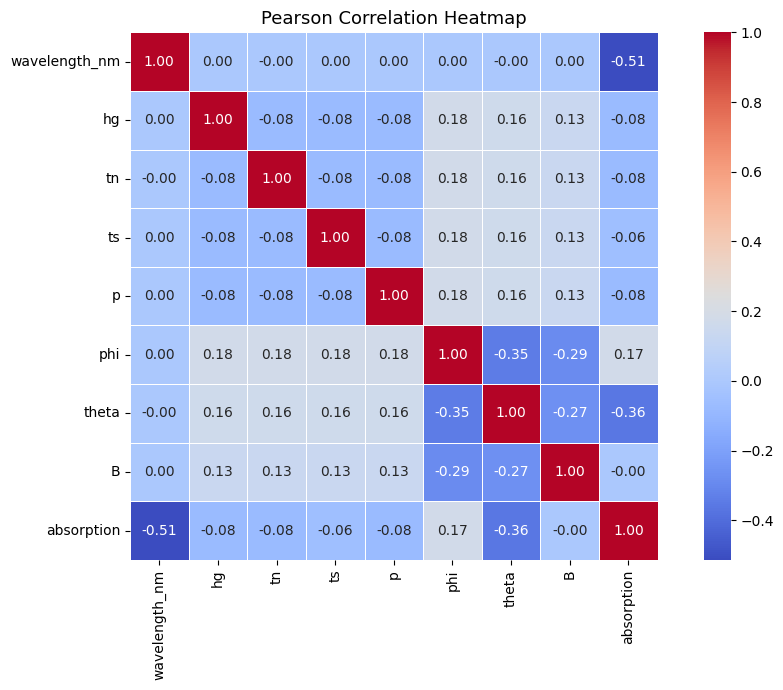

In [ ]:
plt.figure(figsize=(10, 7))
corr = df[features + [target]].corr(method='pearson')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5)
plt.title("Pearson Correlation Heatmap", fontsize=13)
plt.tight_layout()
plt.savefig("fig11_heatmap.png", dpi=150)
plt.show()

HV -50,60,70;

In [ ]:
# Cell 8 — Train all models across HV-50, HV-60, HV-70
splits  = {"HV-50": 0.50, "HV-60": 0.60, "HV-70": 0.70}
results = {}

for hv_name, train_frac in splits.items():
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_scaled, y, train_size=train_frac, random_state=42)
    results[hv_name] = {}

    def record(name, model):
        t0 = time.time()
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)
        results[hv_name][name] = {
            "R2":   float(r2_score(y_te, pred)),
            "MAE":  float(mean_absolute_error(y_te, pred)),
            "MSE":  float(mean_squared_error(y_te, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
            "time": round(time.time() - t0, 2)
        }
        print(f"  {name}: R²={results[hv_name][name]['R2']:.6f}  "
              f"RMSE={results[hv_name][name]['RMSE']:.6f}  "
              f"time={results[hv_name][name]['time']}s")

    print(f"\n{'='*50}")
    print(f"  {hv_name}  (training on {int(train_frac*100)}% of data)")
    print(f"{'='*50}")

    record("XGBoost",
           xgb.XGBRegressor(n_estimators=300, learning_rate=0.05,
                             max_depth=6, verbosity=0, random_state=42))

    record("GradientBoost",
           GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                      max_depth=5, random_state=42))

    record("Polynomial",
           Pipeline([("poly", PolynomialFeatures(degree=6)),
                     ("ridge", Ridge(alpha=0.1))]))

print("\n✓ All models trained!")

# Print summary table
print("\n" + "="*65)
print(f"{'Model':<15} {'HV':<8} {'R2':>10} {'MAE':>12} {'RMSE':>12}")
print("="*65)
for hv in ["HV-50","HV-60","HV-70"]:
    for model in ["XGBoost","GradientBoost","Polynomial"]:
        r = results[hv][model]
        print(f"{model:<15} {hv:<8} {r['R2']:>10.6f} "
              f"{r['MAE']:>12.6f} {r['RMSE']:>12.6f}")
print("="*65)


  HV-50  (training on 50% of data)
  XGBoost: R²=0.448079  RMSE=0.081651  time=1.93s
  GradientBoost: R²=0.447603  RMSE=0.081686  time=5.98s
  Polynomial: R²=0.462346  RMSE=0.080589  time=16.26s

  HV-60  (training on 60% of data)
  XGBoost: R²=0.450375  RMSE=0.081719  time=1.08s
  GradientBoost: R²=0.450047  RMSE=0.081744  time=8.04s
  Polynomial: R²=0.463228  RMSE=0.080758  time=21.92s

  HV-70  (training on 70% of data)
  XGBoost: R²=0.450787  RMSE=0.081472  time=2.05s
  GradientBoost: R²=0.449364  RMSE=0.081577  time=9.75s
  Polynomial: R²=0.463400  RMSE=0.080531  time=21.33s

✓ All models trained!

Model           HV               R2          MAE         RMSE
XGBoost         HV-50      0.448079     0.038301     0.081651
GradientBoost   HV-50      0.447603     0.038417     0.081686
Polynomial      HV-50      0.462346     0.040202     0.080589
XGBoost         HV-60      0.450375     0.038223     0.081719
GradientBoost   HV-60      0.450047     0.038314     0.081744
Polynomial      

pearson heatmap

Metrics

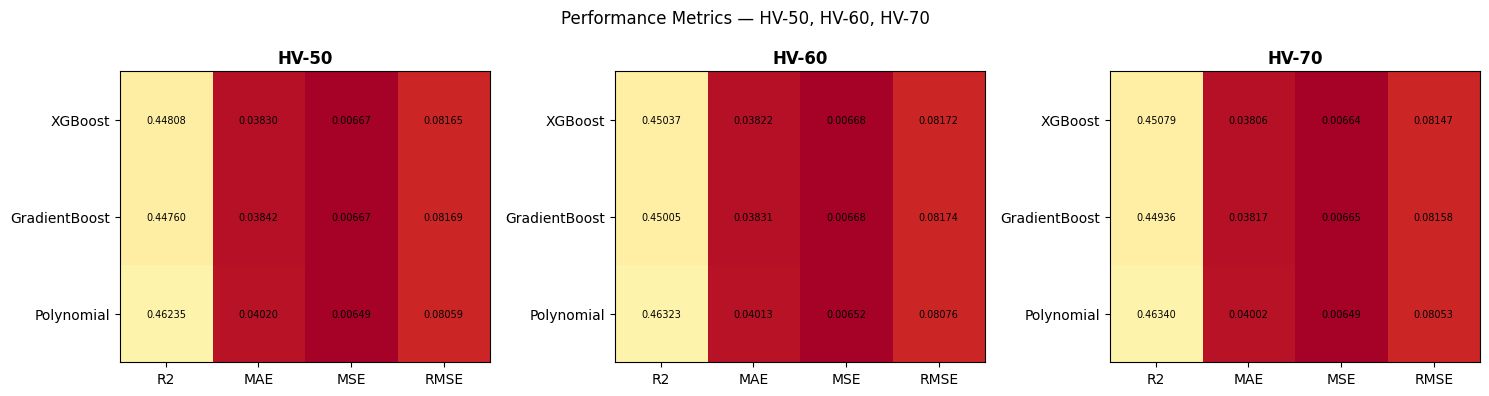

In [ ]:
metrics_list = ["R2", "MAE", "MSE", "RMSE"]
models_list  = ["XGBoost", "GradientBoost", "Polynomial"]
hv_list      = ["HV-50", "HV-60", "HV-70"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, hv in enumerate(hv_list):
    ax = axes[col]
    data = np.array([[results[hv][m][k] for k in metrics_list]
                      for m in models_list])
    ax.imshow(data, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(metrics_list)
    ax.set_yticks(range(3)); ax.set_yticklabels(models_list)
    ax.set_title(hv, fontweight="bold")
    for i in range(3):
        for j in range(4):
            ax.text(j, i, f"{data[i,j]:.5f}",
                    ha="center", va="center", fontsize=7)

plt.suptitle("Performance Metrics — HV-50, HV-60, HV-70", fontsize=12)
plt.tight_layout()
plt.savefig("fig12_metrics.png", dpi=150)
plt.show()

polynomial fits


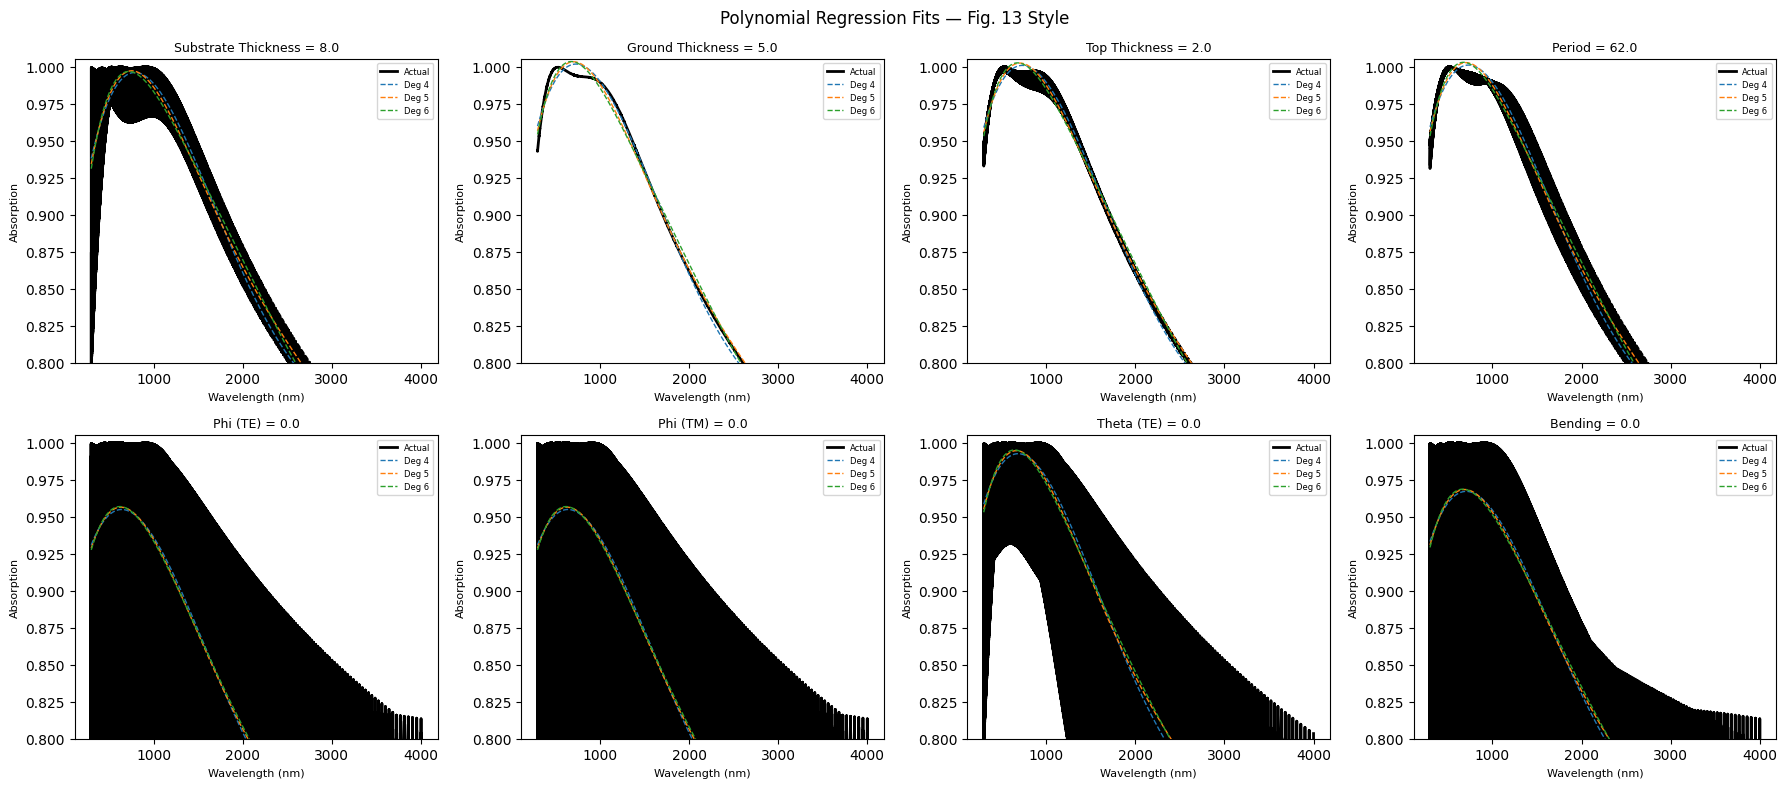

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

# One plot per file/parameter
param_plots = [
    ('ts', 'Substrate Thickness'),
    ('tn', 'Ground Thickness'),
    ('hg', 'Top Thickness'),
    ('p',  'Period'),
    ('phi',   'Phi (TE)'),
    ('phi',   'Phi (TM)'),
    ('theta', 'Theta (TE)'),
    ('B',     'Bending'),
]

for idx, (param, title) in enumerate(param_plots):
    ax = axes[idx]
    vals = sorted(df[param].unique())
    # pick two values for comparison
    pval = vals[0]
    subset = df[df[param] == pval].sort_values('wavelength_nm')
    wl     = subset['wavelength_nm'].values
    actual = subset['absorption'].values

    ax.plot(wl, actual, 'k-', label='Actual', linewidth=2)
    for deg in [4, 5, 6]:
        coeffs = np.polyfit(wl, actual, deg)
        ax.plot(wl, np.polyval(coeffs, wl), '--',
                label=f'Deg {deg}', linewidth=1)

    ax.set_xlabel("Wavelength (nm)", fontsize=8)
    ax.set_ylabel("Absorption", fontsize=8)
    ax.set_title(f"{title} = {pval}", fontsize=9)
    ax.legend(fontsize=6)
    ax.set_ylim(0.80, 1.005)

plt.suptitle("Polynomial Regression Fits — Fig. 13 Style", fontsize=12)
plt.tight_layout()
plt.savefig("fig13_poly.png", dpi=150)
plt.show()

GridSearchCV Hyperparameter Tuning for XGBoost


In [ ]:
from sklearn.model_selection import GridSearchCV

X_tr, X_te, y_tr, y_te = train_test_split(
    X_scaled, y, train_size=0.80, random_state=42)

# XGBoost hyperparameter grid
xgb_params = {
    'n_estimators':  [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth':     [4, 6, 8],
}

print("Tuning XGBoost... (this takes a few minutes)")
xgb_grid = GridSearchCV(
    xgb.XGBRegressor(verbosity=0, random_state=42),
    xgb_params, cv=5, scoring='r2', n_jobs=-1, verbose=1
)
xgb_grid.fit(X_tr, y_tr)
print(f"Best XGBoost params: {xgb_grid.best_params_}")
print(f"Best XGBoost CV R²:  {xgb_grid.best_score_:.6f}")

Tuning XGBoost... (this takes a few minutes)
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best XGBoost params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}
Best XGBoost CV R²:  0.459352


GridSearchCV for GradientBoosting

In [ ]:
gb_params = {
    'n_estimators':  [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth':     [3, 5, 7],
}

print("Tuning GradientBoosting... (this takes a few minutes)")
gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    gb_params, cv=5, scoring='r2', n_jobs=-1, verbose=1
)
gb_grid.fit(X_tr, y_tr)
print(f"Best GB params: {gb_grid.best_params_}")
print(f"Best GB CV R²:  {gb_grid.best_score_:.6f}")

Tuning GradientBoosting... (this takes a few minutes)
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best GB params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
Best GB CV R²:  0.458575


GridSearchCV for Polynomial

In [ ]:
# Cell 14 — FAST VERSION
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

poly_params = {
    'poly__degree': [5, 6],       # only 2 degrees instead of 5
    'ridge__alpha': [0.01, 0.1],  # only 2 values instead of 4
}

print("Tuning Polynomial Regression (fast version)...")
poly_grid = GridSearchCV(
    Pipeline([("poly", PolynomialFeatures()),
              ("ridge", Ridge())]),
    poly_params,
    cv=3,           # 3 folds instead of 5
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
poly_grid.fit(X_tr, y_tr)
print(f"Best Poly params: {poly_grid.best_params_}")
print(f"Best Poly CV R²:  {poly_grid.best_score_:.6f}")

Tuning Polynomial Regression (fast version)...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Poly params: {'poly__degree': 6, 'ridge__alpha': 0.01}
Best Poly CV R²:  0.460207


Evaluate All model

In [ ]:
tuned_models = {
    "XGBoost":      xgb_grid.best_estimator_,
    "GradientBoost": gb_grid.best_estimator_,
    "Polynomial":   poly_grid.best_estimator_,
}

print("\n" + "="*70)
print(f"{'TABLE III — Optimized Model Performance':^70}")
print("="*70)
print(f"{'Model':<16} {'R2':>10} {'MAE':>12} {'MSE':>14} {'RMSE':>12}")
print("-"*70)

table3 = {}
for name, model in tuned_models.items():
    pred = model.predict(X_te)
    r2   = r2_score(y_te, pred)
    mae  = mean_absolute_error(y_te, pred)
    mse  = mean_squared_error(y_te, pred)
    rmse = np.sqrt(mse)
    table3[name] = {"R2": r2, "MAE": mae, "MSE": mse, "RMSE": rmse}
    print(f"{name:<16} {r2:>10.6f} {mae:>12.6f} {mse:>14.8f} {rmse:>12.6f}")

print("="*70)


               TABLE III — Optimized Model Performance                
Model                    R2          MAE            MSE         RMSE
----------------------------------------------------------------------
XGBoost            0.465803     0.038146     0.00652128     0.080754
GradientBoost      0.465825     0.038076     0.00652101     0.080753
Polynomial         0.467832     0.039715     0.00649652     0.080601


Stacking Model

In [ ]:
print("Training Stacking model...")
t0 = time.time()

stacking = StackingRegressor(
    estimators=[
        ("xgb", xgb_grid.best_estimator_),
        ("gb",  gb_grid.best_estimator_),
    ],
    final_estimator=xgb.XGBRegressor(
        n_estimators=100, verbosity=0, random_state=42),
    cv=5
)
stacking.fit(X_tr, y_tr)
t_stack = round(time.time() - t0, 2)

pred_stack = stacking.predict(X_te)
r2_stack   = r2_score(y_te, pred_stack)
mae_stack  = mean_absolute_error(y_te, pred_stack)
mse_stack  = mean_squared_error(y_te, pred_stack)
rmse_stack = np.sqrt(mse_stack)

table3["Stacking"] = {
    "R2": r2_stack, "MAE": mae_stack,
    "MSE": mse_stack, "RMSE": rmse_stack
}

print(f"\nStacking R²  : {r2_stack:.6f}")
print(f"Stacking MAE : {mae_stack:.6f}")
print(f"Stacking MSE : {mse_stack:.8f}")
print(f"Stacking RMSE: {rmse_stack:.6f}")
print(f"Training time: {t_stack}s")

Training Stacking model...

Stacking R²  : 0.454062
Stacking MAE : 0.038996
Stacking MSE : 0.00666462
Stacking RMSE: 0.081637
Training time: 41.67s


CNN model

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Building CNN model (Table IV architecture)...")

# Reshape for CNN input: (samples, features, 1)
X_tr_cnn = X_tr.reshape(X_tr.shape[0], X_tr.shape[1], 1)
X_te_cnn = X_te.reshape(X_te.shape[0], X_te.shape[1], 1)

def build_cnn():
    model = keras.Sequential([
        # Input
        layers.Input(shape=(X_tr.shape[1], 1)),
        # Conv1 — 16 filters, kernel=2
        layers.Conv1D(filters=16, kernel_size=2, activation='relu'),
        # Conv2 — 32 filters, kernel=2
        layers.Conv1D(filters=32, kernel_size=2, activation='relu'),
        # Flatten
        layers.Flatten(),
        # FC1 — 64 units
        layers.Dense(64, activation='relu'),
        # FC2 — regression output
        layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='mse', metrics=['mae'])
    return model

cnn_model = build_cnn()
cnn_model.summary()

# Train
t0 = time.time()
history = cnn_model.fit(
    X_tr_cnn, y_tr,
    validation_split=0.1,
    epochs=50,
    batch_size=64,
    verbose=1
)
t_cnn = round(time.time() - t0, 2)

# Evaluate
pred_cnn  = cnn_model.predict(X_te_cnn).flatten()
r2_cnn    = r2_score(y_te, pred_cnn)
mae_cnn   = mean_absolute_error(y_te, pred_cnn)
mse_cnn   = mean_squared_error(y_te, pred_cnn)
rmse_cnn  = np.sqrt(mse_cnn)

table3["CNN"] = {
    "R2": r2_cnn, "MAE": mae_cnn,
    "MSE": mse_cnn, "RMSE": rmse_cnn
}

print(f"\nCNN R²  : {r2_cnn:.6f}")
print(f"CNN MAE : {mae_cnn:.6f}")
print(f"CNN RMSE: {rmse_cnn:.6f}")
print(f"Training time: {t_cnn}s")

Building CNN model (Table IV architecture)...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 7, 16)          │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 6, 32)          │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,521 (52.82 KB)

 Trainable params: 13,521 (52.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0131 - mae: 0.0648 - val_loss: 0.0066 - val_mae: 0.0491
Epoch 2/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0071 - mae: 0.0503 - val_loss: 0.0066 - val_mae: 0.0489
Epoch 3/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0070 - mae: 0.0492 - val_loss: 0.0068 - val_mae: 0.0533
Epoch 4/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0070 - mae: 0.0489 - val_loss: 0.0064 - val_mae: 0.0427
Epoch 5/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0069 - mae: 0.0481 - val_loss: 0.0066 - val_mae: 0.0506
Epoch 6/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0068 - mae: 0.0470 - val_loss: 0.0075 - val_mae: 0.0621
Epoch 7/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0069 - mae: 0.0472 - val_loss: 0.0064 - val_mae: 0.0461
Epoch 8/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0068 - mae: 0.0465 - val_loss: 0.0067 - val_mae: 0.0514
Epoch 9/50
749/749 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - lo

Final table

In [ ]:
print("\n" + "="*70)
print(f"{'TABLE III — All Models with Optimized Hyperparameters':^70}")
print("="*70)
print(f"{'Model':<16} {'R2':>10} {'MAE':>12} {'MSE':>14} {'RMSE':>12}")
print("-"*70)

for name in ["XGBoost", "GradientBoost", "Polynomial", "Stacking", "CNN"]:
    r = table3[name]
    print(f"{name:<16} {r['R2']:>10.6f} {r['MAE']:>12.6f} "
          f"{r['MSE']:>14.8f} {r['RMSE']:>12.6f}")

print("="*70)
print(f"\n→ Best model: {max(table3, key=lambda x: table3[x]['R2'])}")


        TABLE III — All Models with Optimized Hyperparameters         
Model                    R2          MAE            MSE         RMSE
----------------------------------------------------------------------
XGBoost            0.465803     0.038146     0.00652128     0.080754
GradientBoost      0.465825     0.038076     0.00652101     0.080753
Polynomial         0.467832     0.039715     0.00649652     0.080601
Stacking           0.454062     0.038996     0.00666462     0.081637
CNN                0.462146     0.039239     0.00656593     0.081030

→ Best model: Polynomial


Training Time Table

In [ ]:
# Re-run with timing for default vs optimized hyperparameters
print("\n" + "="*65)
print(f"{'TABLE V — Training Times':^65}")
print("="*65)
print(f"{'Model':<22} {'HV':<8} {'Default(s)':>12} {'Optimized(s)':>14}")
print("-"*65)

for hv_name, train_frac in splits.items():
    X_tr2, _, y_tr2, _ = train_test_split(
        X_scaled, y, train_size=train_frac, random_state=42)

    for mname, default_m, opt_m in [
        ("Polynomial",
         Pipeline([("poly", PolynomialFeatures(degree=6)),
                   ("ridge", Ridge())]),
         poly_grid.best_estimator_),
        ("GradientBoost",
         GradientBoostingRegressor(random_state=42),
         gb_grid.best_estimator_),
        ("XGBoost",
         xgb.XGBRegressor(verbosity=0, random_state=42),
         xgb_grid.best_estimator_),
    ]:
        t0 = time.time(); default_m.fit(X_tr2, y_tr2)
        t_def = round(time.time()-t0, 2)

        t0 = time.time(); opt_m.fit(X_tr2, y_tr2)
        t_opt = round(time.time()-t0, 2)

        print(f"{mname:<22} {hv_name:<8} {t_def:>12.2f} {t_opt:>14.2f}")

print("="*65)


                    TABLE V — Training Times                     
Model                  HV         Default(s)   Optimized(s)
-----------------------------------------------------------------
Polynomial             HV-50           15.81          14.79
GradientBoost          HV-50            1.94           4.81
XGBoost                HV-50            0.23           0.24
Polynomial             HV-60           17.63          17.22
GradientBoost          HV-60            2.34           5.61
XGBoost                HV-60            0.28           0.25
Polynomial             HV-70           20.00          20.98
GradientBoost          HV-70            2.72           5.56
XGBoost                HV-70            1.62           0.84


CNN traininh loss plot

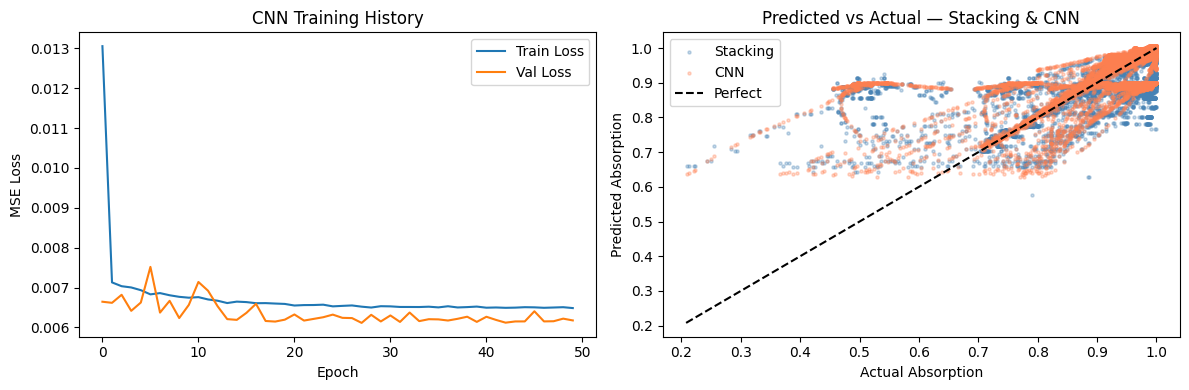

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'],     label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].set_title("CNN Training History")
axes[0].legend()

axes[1].scatter(y_te, pred_stack, alpha=0.3, s=5, color='steelblue',
                label='Stacking')
axes[1].scatter(y_te, pred_cnn,   alpha=0.3, s=5, color='coral',
                label='CNN')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()],
             'k--', linewidth=1.5, label='Perfect')
axes[1].set_xlabel("Actual Absorption")
axes[1].set_ylabel("Predicted Absorption")
axes[1].set_title("Predicted vs Actual — Stacking & CNN")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig_cnn_stacking.png", dpi=150)
plt.show()

In [ ]:
from google.colab import files
for fname in ["fig11_heatmap.png", "fig12_metrics.png",
              "fig13_poly.png", "fig_cnn_stacking.png"]:
    files.download(fname)
    print(f"✓ Downloaded: {fname}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: fig11_heatmap.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

✓ Downloaded: fig13_poly.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: fig_cnn_stacking.png
